# Werkzeuge und Daten importieren

## Bibliotheken importieren

In [1]:
# pandas Bibliothek zur Datenverarbeitung importieren
import pandas as pd

# treech Bibliothek für Decision Tree Anwendungen importieren 
from treech import ClassificationTree as ct

# plotly und cufflinks Bibliotheken zur Datenvisalisierung importieren 
from plotly.offline import iplot
import plotly as py
import cufflinks as cf
cf.go_offline()


## Daten importieren

In [3]:
# CSV-Datei importieren
df_jim = pd.read_csv('Jim_53.csv', sep=';')

In [4]:
#Datensatz anzeigen
df_jim

,Spielen_OnlineSpiele,Tablet_Besitz,Computer_Besitz,FesteKonsole_Besitz,Smartphone_Besitz,E_Reader_Besitz,Nutzen_Twitter,Nutzen_Snapchat,Nutzen_Instagram,Youtube_Musikvideos,Geschlecht,Youtube_LustigeClips,Youtube_Sportvideos,Youtube_ModeBeauty,Youtube_LetsPlay
0,Häufig,Ja,Nein,Ja,Ja,Nein,Selten,Selten,Häufig,Häufig,männlich,Selten,Selten,Selten,Häufig
1,Häufig,Nein,Ja,Nein,Ja,Nein,Selten,Häufig,Häufig,Häufig,männlich,Häufig,Häufig,Selten,Häufig
2,Häufig,Nein,Nein,Ja,Ja,Ja,Häufig,Häufig,Selten,Häufig,männlich,Häufig,Häufig,Selten,Häufig
3,Selten,Nein,Nein,Nein,Ja,Nein,Selten,Selten,Häufig,Selten,weiblich,Selten,Selten,Selten,Selten
4,Selten,Nein,Nein,Ja,Ja,Nein,Selten,Häufig,Häufig,Selten,männlich,Selten,Häufig,Selten,Selten
5,Selten,Nein,Nein,Nein,Ja,Nein,Selten,Häufig,Häufig,Häufig,weiblich,Selten,Selten,Selten,Selten
6,Häufig,Nein,Ja,Ja,Ja,Nein,Selten,Häufig,Häufig,Häufig,männlich,Häufig,Selten,Selten,Häufig
7,Häufig,Ja,Nein,Ja,Ja,Ja,Selten,Häufig,Häufig,Häufig,weiblich,Selten,Selten,Selten,Selten
8,Selten,Nein,Nein,Nein,Ja,Ja,Häufig,Häufig,Häufig,Selten,weiblich,Häufig,Selten,Selten,Selten
9,Selten,Nein,Nein,Ja,Ja,Ja,Selten,Häufig,Häufig,Selten,weiblich,Selten,Häufig,Selten,Selten


# Entscheidungsbaum trainieren

In [9]:
# Decision Tree initialisieren
tree_jim = ct.DecisionTree(data = df_jim, target = "Spielen_OnlineSpiele")

In [11]:
# Decision Tree trainieren 
tree_jim.grow_tree(crit='missclassification_error')

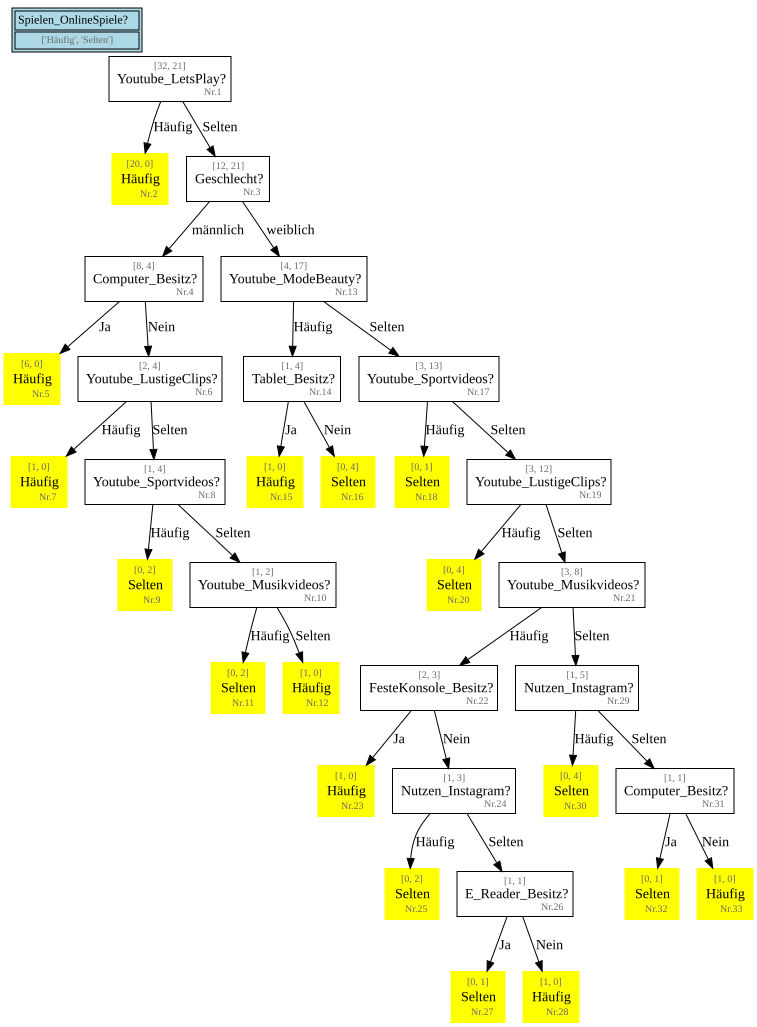

In [13]:
# Decision Tree anzeigen
tree_jim.print_tree()

In [15]:
tree_jim.prediction_accuracy(df_jim)

1.0

# Entscheidungsbaum mit Testdaten prüfen

In [18]:
df_jim_test = pd.read_csv('Jim_binaer_test.csv', sep=';')

In [20]:
df_jim_test

,Spielen_OnlineSpiele,Geschlecht,Nutzen_Twitter,Nutzen_Snapchat,Nutzen_Instagram,Youtube_Musikvideos,Youtube_LetsPlay,Youtube_LustigeClips,Youtube_Sportvideos,Youtube_ModeBeauty,Tablet_Besitz,Computer_Besitz,FesteKonsole_Besitz,Smartphone_Besitz,E_Reader_Besitz
0,Häufig,männlich,Selten,Häufig,Häufig,Häufig,Häufig,Häufig,Selten,Selten,Nein,Nein,Ja,Ja,Nein
1,Häufig,männlich,Selten,Selten,Häufig,Häufig,Häufig,Selten,Selten,Selten,Ja,Nein,Ja,Ja,Nein
2,Selten,weiblich,Selten,Selten,Häufig,Selten,Selten,Selten,Selten,Selten,Nein,Nein,Nein,Ja,Nein
3,Häufig,männlich,Selten,Selten,Selten,Häufig,Häufig,Selten,Selten,Selten,Nein,Nein,Nein,Ja,Nein
4,Häufig,männlich,Selten,Häufig,Häufig,Häufig,Häufig,Häufig,Häufig,Selten,Nein,Ja,Nein,Ja,Nein
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,Häufig,männlich,Häufig,Selten,Häufig,Selten,Selten,Selten,Selten,Selten,Ja,Ja,Ja,Ja,Nein
146,Selten,weiblich,Selten,Selten,Selten,Häufig,Selten,Häufig,Selten,Selten,Nein,Ja,Nein,Nein,Nein
147,Häufig,männlich,Häufig,Häufig,Häufig,Häufig,Häufig,Selten,Selten,Selten,Nein,Nein,Ja,Ja,Nein
148,Häufig,männlich,Häufig,Häufig,Häufig,Häufig,Häufig,Häufig,Häufig,Selten,Nein,Ja,Ja,Ja,Nein


In [22]:
tree_jim.prediction_accuracy(df_jim_test)

0.7133333333333334

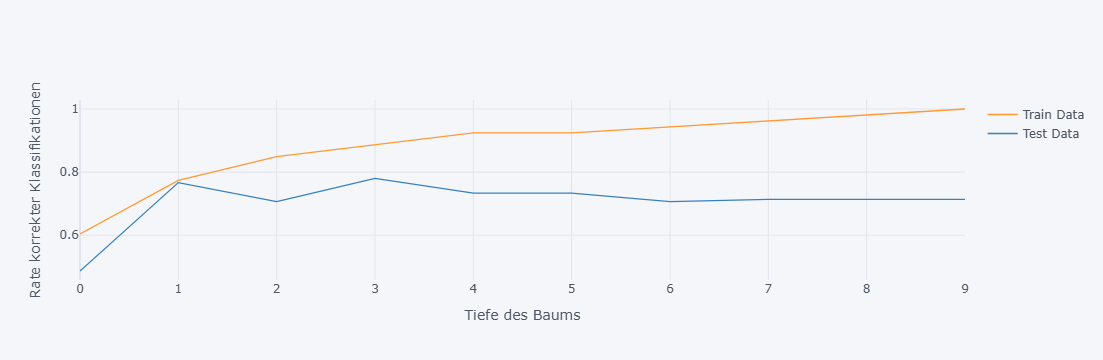

In [24]:
tree_jim.evaluation_depth(df_jim, df_jim_test).iplot(xTitle='Tiefe des Baums', yTitle='Rate korrekter Klassifikationen')